# Exploratory data analysis

In [2]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DATA_PATH

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = pd.read_csv(DATA_PATH)
target = 'Performance_Score'
df.shape

(100000, 20)

## 1. Salary vs performance

`Monthly_Salary` is the first suspect. Distribution per score, then summary statistics.

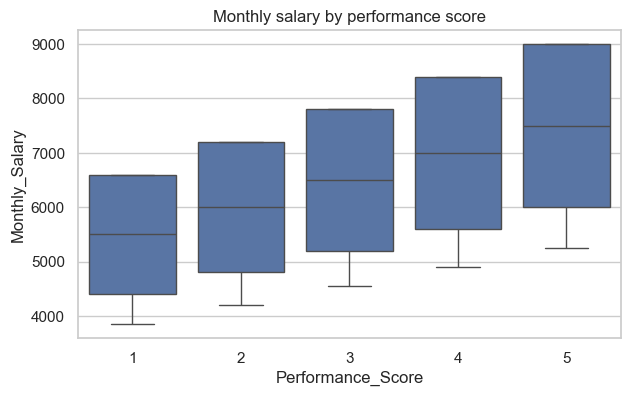

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x=target, y='Monthly_Salary', ax=ax)
ax.set_title('Monthly salary by performance score')
plt.show()

In [4]:
df.groupby(target)['Monthly_Salary'].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
Performance_Score,,,,,,,,
1,20120.0,5422.0,991.0,3850.0,4400.0,5500.0,6600.0,6600.0
2,20013.0,5900.0,1088.0,4200.0,4800.0,6000.0,7200.0,7200.0
3,19999.0,6410.0,1176.0,4550.0,5200.0,6500.0,7800.0,7800.0
4,19940.0,6898.0,1266.0,4900.0,5600.0,7000.0,8400.0,8400.0
5,19928.0,7398.0,1350.0,5250.0,6000.0,7500.0,9000.0,9000.0


In [5]:
print('distinct salary values :', df['Monthly_Salary'].nunique())
sorted(df['Monthly_Salary'].unique())[:20]

distinct salary values : 28


[np.float64(3850.0),
 np.float64(4200.0),
 np.float64(4400.0),
 np.float64(4550.0),
 np.float64(4800.0),
 np.float64(4900.0),
 np.float64(4950.0),
 np.float64(5200.0),
 np.float64(5250.0),
 np.float64(5400.0),
 np.float64(5500.0),
 np.float64(5600.0),
 np.float64(5850.0),
 np.float64(6000.0),
 np.float64(6050.0),
 np.float64(6300.0),
 np.float64(6500.0),
 np.float64(6600.0),
 np.float64(6750.0),
 np.float64(7000.0)]

## 2. All numeric features vs performance

Mean of each numeric feature per score, standardized (z-score of the column) so that columns on different scales can be compared. A feature with a real relation would show a trend across scores.

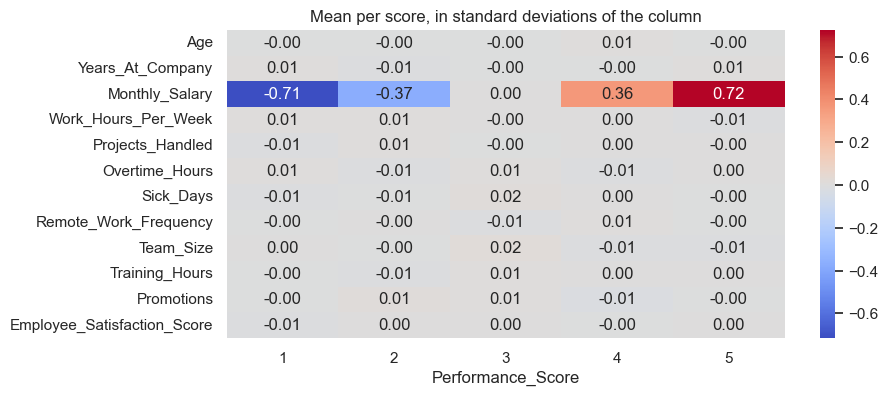

In [6]:
num_cols = df.select_dtypes(include='number').columns.drop([target, 'Employee_ID'])
means = df.groupby(target)[num_cols].mean()
z = (means - df[num_cols].mean()) / df[num_cols].std()

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(z.T, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Mean per score, in standard deviations of the column')
plt.show()

## 3. Categorical features vs performance

For each category, share of each score (rows sum to 1). If a column were unrelated to the target, every row would be close to 0.20.

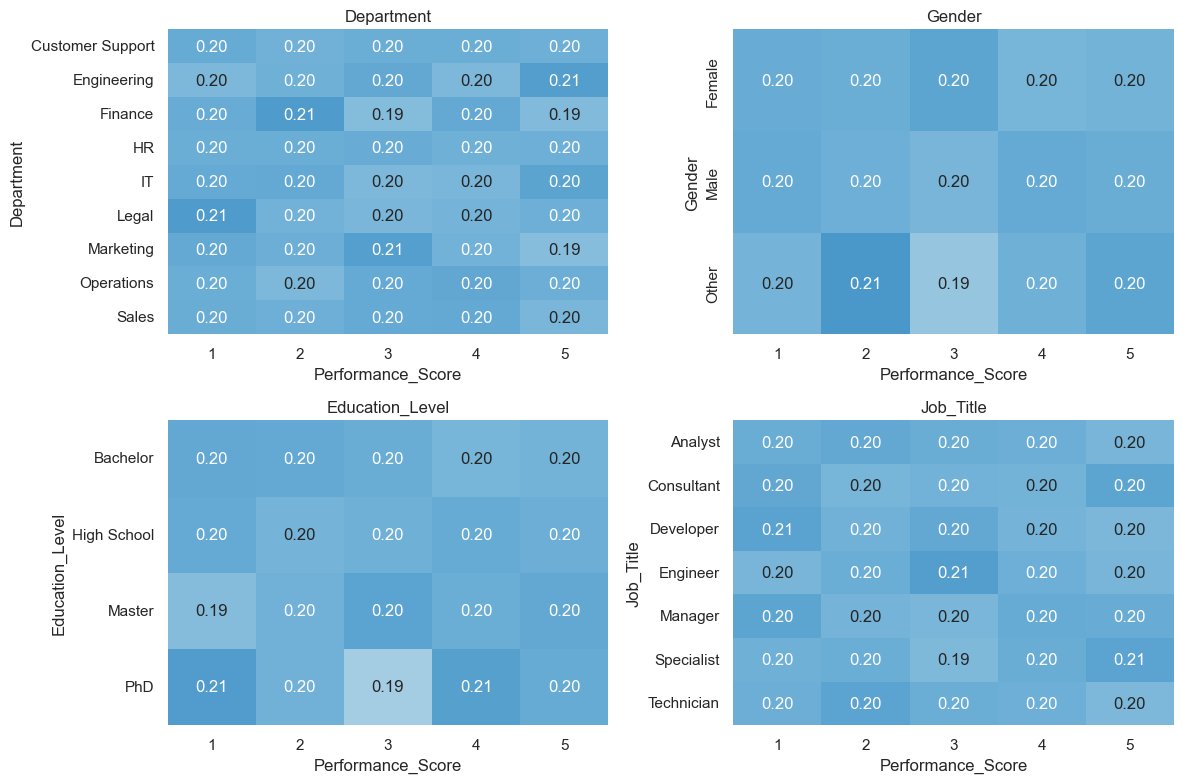

In [7]:
cat_cols = ['Department', 'Gender', 'Education_Level', 'Job_Title']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    share = pd.crosstab(df[col], df[target], normalize='index')
    sns.heatmap(share, annot=True, fmt='.2f', cmap='Blues', vmin=0.15, vmax=0.25, ax=ax, cbar=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 4. Workload vs performance

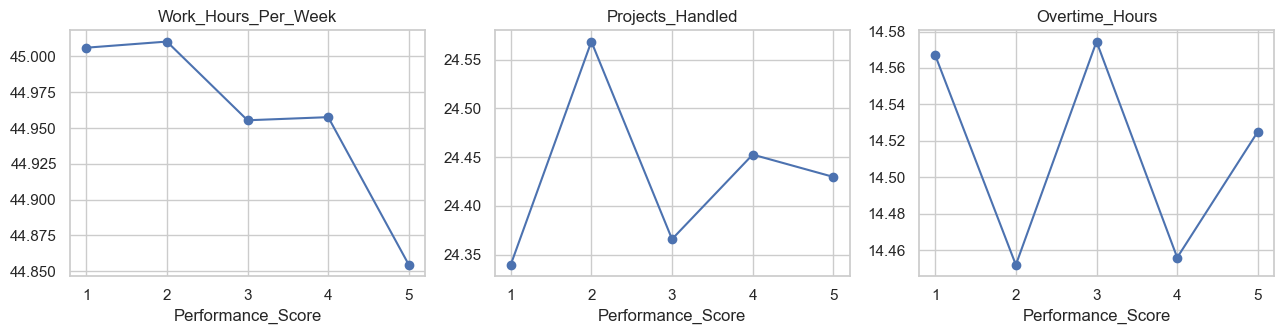

In [8]:
workload = ['Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, workload):
    df.groupby(target)[col].mean().plot(marker='o', ax=ax)
    ax.set_title(col)
    ax.set_xlabel(target)
plt.tight_layout()
plt.show()

## 5. Salary and job title

Salary may depend on `Job_Title` rather than on performance directly. Quick look at both.

In [9]:
df.groupby('Job_Title')['Monthly_Salary'].agg(['mean', 'min', 'max']).round(0).sort_values('mean')

,mean,min,max
Job_Title,,,
Technician,4545.0,3850.0,5250.0
Analyst,5196.0,4400.0,6000.0
Specialist,5855.0,4950.0,6750.0
Developer,6490.0,5500.0,7500.0
Consultant,7152.0,6050.0,8250.0
Manager,7798.0,6600.0,9000.0
Engineer,7799.0,6600.0,9000.0


In [10]:
pd.crosstab(df['Monthly_Salary'], df[target], normalize='index').round(2).head(15)

Performance_Score,1,2,3,4,5
Monthly_Salary,,,,,
3850.0,1.0,0.0,0.0,0.0,0.0
4200.0,0.0,1.0,0.0,0.0,0.0
4400.0,1.0,0.0,0.0,0.0,0.0
4550.0,0.0,0.0,1.0,0.0,0.0
4800.0,0.0,1.0,0.0,0.0,0.0
4900.0,0.0,0.0,0.0,1.0,0.0
4950.0,1.0,0.0,0.0,0.0,0.0
5200.0,0.0,0.0,1.0,0.0,0.0
5250.0,0.0,0.0,0.0,0.0,1.0


## Findings

- **Salary is derived from the target.** Monthly_Salary takes only 28 distinct values, and almost each value maps to a single score (crosstab). Within a job title, salary follows a grid: base(Job_Title) × (1 + 0.1 × Performance_Score), e.g. Technician 3850/4200/4550/4900/5250, Manager 6600/7200/7800/8400/9000. Salary + Job_Title therefore (almost) determine the score. This is target leakage by construction, not a weak correlation. Mean salary per score goes from -0.71 to +0.72 standard deviations.
- Residual ambiguity comes from collisions between job titles (e.g. 6000 = Analyst x 1.5 = Developer x 1.2) and from Manager and Engineer sharing the same grid.
- **Every other numeric feature is flat**: means per score stay within ±0.02 standard deviations (Age, Years_At_Company, workload, Sick_Days, Remote_Work_Frequency, Team_Size, Training_Hours, Promotions, Satisfaction).
- **Categorical features are flat**: Department, Gender, Education_Level and Job_Title all give score shares between 0.19 and 0.21, which is within sampling noise. Job_Title relates to salary but not directly to the score.
- Consequence for modeling: every model will be run with and without Monthly_Salary, and results with salary must be read as "recovering a formula", not as a real predictive signal. Without salary, little signal is expected, which suggests the data is synthetic.